In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!wget -q -O PBC.zip "https://data.mendeley.com/public-files/datasets/snkd93bnjr/files/2fc38728-2ae7-4a62-a857-032af82334c3/file_downloaded"

!rm -rf data/PBC_dataset_normal_DIB
!rm -rf data/__MACOSX
!mkdir -p data

!unzip -q PBC.zip -x "__MACOSX/*" -d data/

In [3]:
import os

bad_file = "data/PBC_dataset_normal_DIB/neutrophil/.DS_169665.jpg"

if os.path.exists(bad_file):
    os.remove(bad_file)

print("Invalid file removed:", not os.path.exists(bad_file))

Invalid file removed: True


In [4]:
csv_file = "/content/drive/MyDrive/Hemavision/pbc_master_split.csv"
dataset_root = "data/PBC_dataset_normal_DIB"

In [5]:
import pandas as pd

df = pd.read_csv(csv_file)

print(df.shape)
print(df["split"].value_counts())
print(df.head())

(17092, 4)
split
train    11964
val       2564
test      2564
Name: count, dtype: int64
                     file_path  label_idx  split    class_name
0    neutrophil/BNE_297581.jpg          6  train    neutrophil
1  erythroblast/ERB_560016.jpg          2  train  erythroblast
2       basophil/BA_547170.jpg          0  train      basophil
3            ig/MMY_913911.jpg          3  train            ig
4       basophil/BA_515691.jpg          0  train      basophil


In [6]:
import os
from PIL import Image
from torch.utils.data import Dataset

class PBCDataset(Dataset):
    def __init__(self, dataframe, dataset_root, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.dataset_root = dataset_root
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_path = os.path.join(
            self.dataset_root,
            row["file_path"]
        )

        image = Image.open(image_path).convert("RGB")
        label = int(row["label_idx"])

        if self.transform:
            image = self.transform(image)

        return image, label

In [7]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [8]:
train_df = df[df["split"] == "train"]
val_df = df[df["split"] == "val"]
test_df = df[df["split"] == "test"]

print(len(train_df), len(val_df), len(test_df))

11964 2564 2564


In [9]:
train_dataset = PBCDataset(
    train_df,
    dataset_root,
    transform=train_transform
)

val_dataset = PBCDataset(
    val_df,
    dataset_root,
    transform=eval_transform
)

test_dataset = PBCDataset(
    test_df,
    dataset_root,
    transform=eval_transform
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 11964
Validation: 2564
Test: 2564


In [10]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

In [11]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 8 labels:", labels[:8])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First 8 labels: tensor([7, 5, 6, 6, 2, 2, 1, 6])


In [12]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [13]:
class_names = (
    df[["label_idx", "class_name"]]
    .drop_duplicates()
    .sort_values("label_idx")["class_name"]
    .tolist()
)

num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)

Classes: ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
Number of classes: 8


In [14]:
weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)

model = model.to(device)

print(model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 237MB/s]


Linear(in_features=512, out_features=8, bias=True)


In [15]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr = 1e-4,
    weight_decay = 1e-4
)

num_epochs = 10

print("Loss: CrossEntropyLoss")
print("Optimizer: AdamW")
print("Learning rate:", 1e-4)
print("Epochs:", num_epochs)

Loss: CrossEntropyLoss
Optimizer: AdamW
Learning rate: 0.0001
Epochs: 10


In [16]:
checkpoint_path = (
    "/content/drive/MyDrive/Hemavision/"
    "hemavision_resnet18_v1_best.pth"
)

print("Best model will be saved to:")
print(checkpoint_path)

Best model will be saved to:
/content/drive/MyDrive/Hemavision/hemavision_resnet18_v1_best.pth


In [17]:
import os

# 1. Verify numeric label to class name mapping
label_mapping = (
    df[["label_idx", "class_name"]]
    .drop_duplicates()
    .sort_values("label_idx")
)
print("Verified Label Mapping:")
print(label_mapping.to_string(index=False))

# 2. Ensure Google Drive checkpoint directory exists
os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)
print("\nCheckpoint folder ready:", os.path.dirname(checkpoint_path))

Verified Label Mapping:
 label_idx   class_name
         0     basophil
         1   eosinophil
         2 erythroblast
         3           ig
         4   lymphocyte
         5     monocyte
         6   neutrophil
         7     platelet

Checkpoint folder ready: /content/drive/MyDrive/Hemavision


In [18]:
import time

best_val_accuracy = 0.0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

print("Starting Model v1 training...")

start_time = time.time()

for epoch in range(num_epochs):

    epoch_start = time.time()

    # TRAINING
    model.train()

    running_train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()


    train_loss = running_train_loss / train_total
    train_accuracy = train_correct / train_total

    # VALIDATION
    model.eval()

    running_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()


    val_loss = running_val_loss / val_total
    val_accuracy = val_correct / val_total

    # RECORD RESULTS
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_accuracy)
    history["val_acc"].append(val_accuracy)


    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {epoch+1:02d}/{num_epochs:02d} "
        f"[{epoch_time:.0f}s] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy*100:.2f}%"
    )

    # SAVE BEST MODEL
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "val_accuracy": best_val_accuracy,
            "class_names": class_names
        }, checkpoint_path)

        print(
            f"  --> Saved new best model "
            f"(Val Acc: {best_val_accuracy*100:.2f}%)"
        )


total_time = (time.time() - start_time) / 60

print()
print(f"Training complete in {total_time:.1f} minutes")
print(f"Best validation accuracy: {best_val_accuracy*100:.2f}%")

Starting Model v1 training...
Epoch 01/10 [47s] | Train Loss: 0.2073 | Train Acc: 93.55% | Val Loss: 0.0627 | Val Acc: 98.05%
  --> Saved new best model (Val Acc: 98.05%)
Epoch 02/10 [46s] | Train Loss: 0.0685 | Train Acc: 97.66% | Val Loss: 0.0670 | Val Acc: 97.82%
Epoch 03/10 [47s] | Train Loss: 0.0500 | Train Acc: 98.28% | Val Loss: 0.0479 | Val Acc: 98.48%
  --> Saved new best model (Val Acc: 98.48%)
Epoch 04/10 [47s] | Train Loss: 0.0449 | Train Acc: 98.43% | Val Loss: 0.0463 | Val Acc: 98.32%
Epoch 05/10 [47s] | Train Loss: 0.0382 | Train Acc: 98.78% | Val Loss: 0.0749 | Val Acc: 97.43%
Epoch 06/10 [46s] | Train Loss: 0.0299 | Train Acc: 99.11% | Val Loss: 0.0469 | Val Acc: 98.60%
  --> Saved new best model (Val Acc: 98.60%)
Epoch 07/10 [47s] | Train Loss: 0.0312 | Train Acc: 98.88% | Val Loss: 0.0600 | Val Acc: 98.09%
Epoch 08/10 [46s] | Train Loss: 0.0226 | Train Acc: 99.27% | Val Loss: 0.0491 | Val Acc: 98.48%
Epoch 09/10 [47s] | Train Loss: 0.0205 | Train Acc: 99.34% | Val Lo

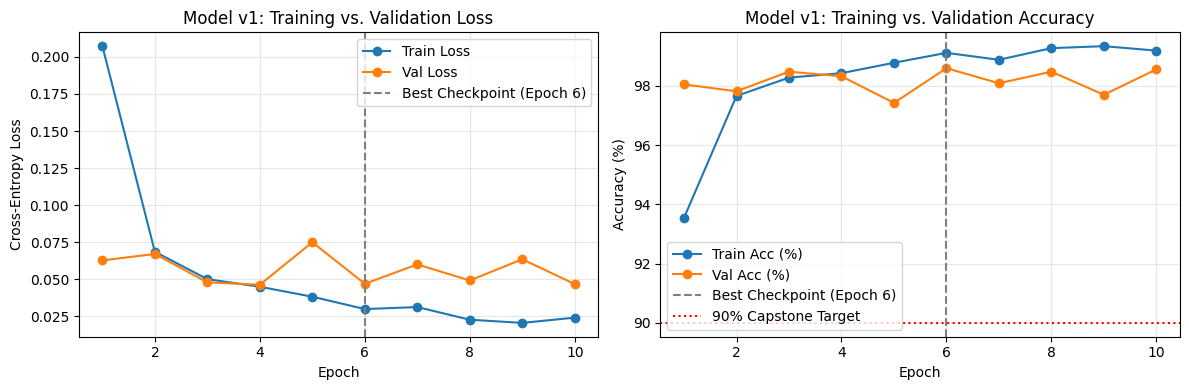

In [19]:
import matplotlib.pyplot as plt

epochs_range = range(1, num_epochs + 1)

plt.figure(figsize=(12, 4))

# 1. Loss Curve
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], label="Train Loss", marker="o")
plt.plot(epochs_range, history["val_loss"], label="Val Loss", marker="o")
plt.axvline(x=6, color="gray", linestyle="--", label="Best Checkpoint (Epoch 6)")
plt.title("Model v1: Training vs. Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)

# 2. Accuracy Curve
plt.subplot(1, 2, 2)
plt.plot(epochs_range, [a * 100 for a in history["train_acc"]], label="Train Acc (%)", marker="o")
plt.plot(epochs_range, [a * 100 for a in history["val_acc"]], label="Val Acc (%)", marker="o")
plt.axvline(x=6, color="gray", linestyle="--", label="Best Checkpoint (Epoch 6)")
plt.axhline(y=90, color="red", linestyle=":", label="90% Capstone Target")
plt.title("Model v1: Training vs. Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Hemavision/model_v1_training_curves.png", dpi=300)
plt.show()